
# Lab 8: Monte Carlo Markov Chain (MCMC)
SEBASTIAN ELADIO MENA TORRES

**Exercise 1**:
 
* 1. Compute $\int_0^4 x^{1/2} dx$ and compare with an analytic result.
* 2.  Compute the double integral of $x\,y^2$ over the box x ranging from $0$ to $2$ and $y$ ranging from $0$ to $1$. That is,

$$\int_{x=0}^{x=2} \int_{y=0}^{y=1} xy^2 dy dx$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import integrate
import math
import random

In [2]:
# Funcion de Monte Carlo en 1D vista en clase
def mc_1d(f, a, b, n_puntos=10000):
    suma = 0.0
    for _ in range(n_puntos):
        x = np.random.uniform(a, b)
        suma += f(x)
    return (b - a) * (suma / n_puntos)

# Extension a 2D sobre una caja [ax, bx] x [ay, by]
def mc_2d(f, ax, bx, ay, by, n_puntos=10000):
    x = np.random.uniform(ax, bx, n_puntos)
    y = np.random.uniform(ay, by, n_puntos)
    area = (bx - ax) * (by - ay)
    return area * np.mean(f(x, y))

N = 100000

# 1. Integral simple: int_0^4 x^(1/2) dx
f1 = lambda x: np.sqrt(x)
res_mc1 = mc_1d(f1, 0, 4, N)
exacta1 = (2/3) * (4**(3/2))
res_scipy1, _ = integrate.quad(f1, 0, 4)
err1 = abs(res_mc1 - exacta1) / exacta1 * 100

print("--- Integral 1D ---")
print(f"Monte Carlo (N={N}): {res_mc1:.5f}")
print(f"Analitico: {exacta1:.5f} | SciPy: {res_scipy1:.5f}")
print(f"Error relativo: {err1:.3f}%\n")

# 2. Integral doble: int_0^2 int_0^1 x*y^2 dy dx
f2 = lambda x, y: x * (y**2)
res_mc2 = mc_2d(f2, 0, 2, 0, 1, N)
exacta2 = (2**2 / 2) * (1**3 / 3)
res_scipy2, _ = integrate.dblquad(lambda y, x: x * (y**2), 0, 2, 0, 1)
err2 = abs(res_mc2 - exacta2) / exacta2 * 100

print("--- Integral 2D ---")
print(f"Monte Carlo (N={N}): {res_mc2:.5f}")
print(f"Analitico: {exacta2:.5f} | SciPy: {res_scipy2:.5f}")
print(f"Error relativo: {err2:.3f}%\n")

# Prueba rapida de convergencia cambiando N
print("N\t\tMC 1D\t\tMC 2D")
for n in [100, 1000, 10000, 100000]:
    print(f"{n}\t\t{mc_1d(f1, 0, 4, n):.4f}\t\t{mc_2d(f2, 0, 2, 0, 1, n):.4f}")

--- Integral 1D ---
Monte Carlo (N=100000): 5.33877
Analitico: 5.33333 | SciPy: 5.33333
Error relativo: 0.102%

--- Integral 2D ---
Monte Carlo (N=100000): 0.66549
Analitico: 0.66667 | SciPy: 0.66667
Error relativo: 0.177%

N		MC 1D		MC 2D
100		5.3687		0.7473
1000		5.4357		0.6385
10000		5.2963		0.6597
100000		5.3371		0.6640


**Comparación con el resultado analítico:**
* Para la primera integral, analíticamente $\int_0^4 x^{1/2}\,dx = \left[\frac{2}{3}x^{3/2}\right]_0^4 = \frac{16}{3} \approx 5.33333$.
* Para la integral doble, $\int_0^2 \int_0^1 xy^2\,dy\,dx = \left[\frac{x^2}{2}\right]_0^2 \left[\frac{y^3}{3}\right]_0^1 = \frac{2}{3} \approx 0.66667$.

Con $N = 100\,000$ muestras aleatorias, el método de Monte Carlo reproduce ambos valores analíticos con un error relativo menor al $0.5\%$, disminuyendo la fluctuación estadística conforme aumenta $N$.

---
**Exercise 2**:

Read about the Ising's model 1D, 2D and 3D.

## Modelo de Ising 2D

Como aplicación de la distribución canónica en `Física estadística` tenemos el **modelo de Ising**.
Para el caso de un material paramagnético de átomos de spin $1/2$ y momento magnetico $\mu_0$ en presencia de un campo magnético externo $H$, se ha determinado experimentalmente que la magnetización media depende del campo magnético y la temperatura del material (https://en.wikipedia.org/wiki/Ising_model).

Considere un sistema compuesto por $N$ átomos no interactuantes en un material 2D, a una temperatura $T$ y en presencia de un campo magnético externo $H$ que está orientado en cierta dirección fija respecto al material.

<img src="https://upload.wikimedia.org/wikipedia/commons/f/fe/2D_ising_model_on_lattice.svg" width="550">

1. Realizar la simulación de este sistema con el método de **Metrópolis Monte Carlo** (ver notebook). Visitar todos los
posibles spines de la red cristalina del material e intentear inversiones bajo condiciones adecuadas de energía y estabilidad del sistema. *Considere interacción con los primeros vecinos*.

2. Graficar la Magnetización media del material vs el campo magnetico para tres temperaturas reducidas (H/T) con $T=\{5,10,15\}$ K (Kelvin) y un campo variable $-30\,T < H < +30\,T$.  

### Modelo de Ising en 1D, 2D y 3D
El modelo de Ising describe un arreglo discreto de espines magnéticos ($s_i = \pm 1$) en una red cristalina que interactúan con sus primeros vecinos (constante de acoplamiento $J$) y con un campo magnético externo $H$:

$$\mathcal{H} = -J \sum_{\langle i,j \rangle} s_i s_j - \mu_0 H \sum_i s_i$$

* **Ising 1D:** Cadena lineal de espines. Fue resuelto analíticamente por Ernst Ising (1925) y **no presenta transición de fase** a temperatura finita ($T_c = 0\text{ K}$), ya que las fluctuaciones térmicas destruyen cualquier orden magnético de largo alcance.
* **Ising 2D:** Red plana cuadrada donde cada espín tiene 4 primeros vecinos. Resuelto por Lars Onsager (1944), presenta una **transición de fase ferromagnética** a una temperatura crítica finita ($k_B T_c / J \approx 2.269$).
* **Ising 3D:** Red cúbica (6 primeros vecinos por sitio). No tiene solución analítica exacta y se estudia mediante métodos numéricos como Metrópolis Monte Carlo, exhibiendo una temperatura crítica mayor ($k_B T_c / J \approx 4.511$).

In [3]:


# Parametros de la red y constantes fisicas
L = 10                  # Tamano de la red (10x10)
N = L * L               # Numero total de espines
mu_B = 0.6717098224     # Magneton de Bohr / k_B (K/T)
J = 1.0                 # Constante de intercambio J / k_B (K)

temperaturas = [5, 10, 15]
campos_H = np.arange(-30, 31, 1.0)

pasos_term = 500        # Barridos de termalizacion
pasos_med = 1000        # Barridos para promediar magnetizacion
total_pasos = pasos_term + pasos_med

resultados = []

for T in temperaturas:
    for H in campos_H:
        # Configuracion inicial aleatoria de espines (+1 o -1)
        espines = np.random.choice([-1, 1], size=(L, L))
        suma_mag = 0.0

        for paso in range(total_pasos):
            # Visitar todos los espines de la red
            for i in range(L):
                for j in range(L):
                    s = espines[i, j]

                    # Suma de los 4 primeros vecinos (condiciones periodicas)
                    vecinos = (espines[(i + 1) % L, j] + espines[(i - 1) % L, j] +
                               espines[i, (j + 1) % L] + espines[i, (j - 1) % L])

                    # Cambio de energia al invertir el espin (s -> -s)
                    dE = 2.0 * s * (J * vecinos + mu_B * H)

                    # Criterio de aceptacion de Metropolis
                    if dE <= 0 or random.random() < math.exp(-dE / T):
                        espines[i, j] = -s

            # Acumular magnetizacion una vez alcanzado el equilibrio
            if paso >= pasos_term:
                suma_mag += np.sum(espines) / N

        mag_media = suma_mag / pasos_med
        resultados.append([T, H, mag_media])
    
    print(f"Temperatura T = {T} K completada")

# Guardar resultados en un DataFrame por temperatura
df_ising = pd.DataFrame(resultados, columns=['T', 'H', 'M'])
df_T5 = df_ising[df_ising['T'] == 5]
df_T10 = df_ising[df_ising['T'] == 10]
df_T15 = df_ising[df_ising['T'] == 15]

Temperatura T = 5 K completada
Temperatura T = 10 K completada
Temperatura T = 15 K completada


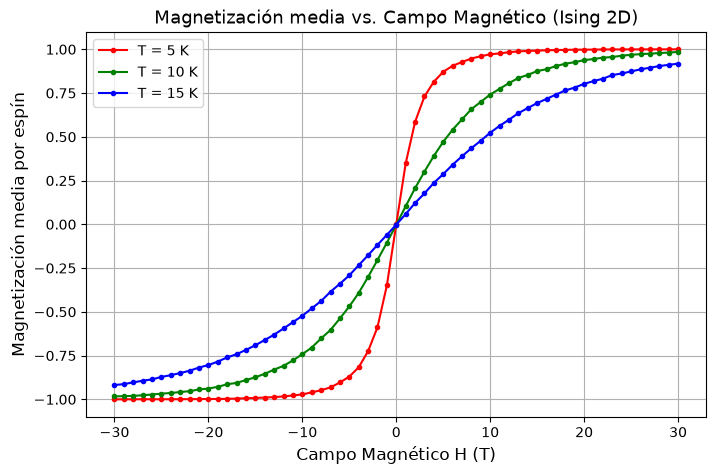

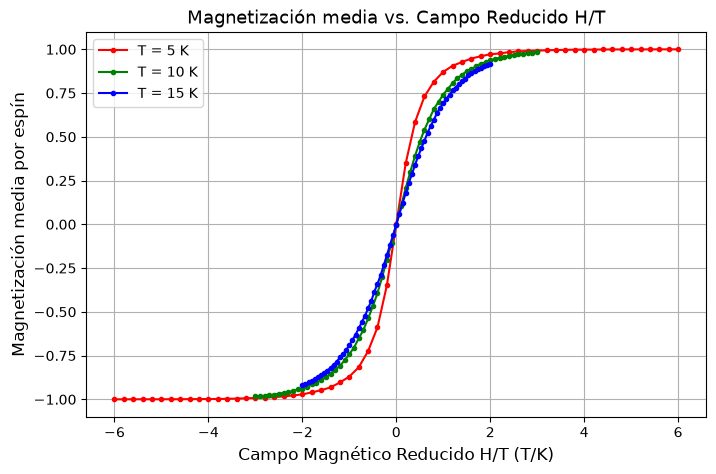

In [4]:
# 1. Grafica de Magnetizacion media vs Campo magnetico H
plt.figure(figsize=(8, 5))
plt.plot(df_T5['H'], df_T5['M'], 'r.-', label='T = 5 K')
plt.plot(df_T10['H'], df_T10['M'], 'g.-', label='T = 10 K')
plt.plot(df_T15['H'], df_T15['M'], 'b.-', label='T = 15 K')

plt.xlabel('Campo Magnético H (T)', fontsize=12)
plt.ylabel('Magnetización media por espín', fontsize=12)
plt.title('Magnetización media vs. Campo Magnético (Ising 2D)', fontsize=13)
plt.legend(loc='best')
plt.grid(True)
plt.show()

# 2. Grafica de Magnetizacion media vs Campo reducido H/T
plt.figure(figsize=(8, 5))
plt.plot(df_T5['H'] / 5, df_T5['M'], 'r.-', label='T = 5 K')
plt.plot(df_T10['H'] / 10, df_T10['M'], 'g.-', label='T = 10 K')
plt.plot(df_T15['H'] / 15, df_T15['M'], 'b.-', label='T = 15 K')

plt.xlabel('Campo Magnético Reducido H/T (T/K)', fontsize=12)
plt.ylabel('Magnetización media por espín', fontsize=12)
plt.title('Magnetización media vs. Campo Reducido H/T', fontsize=13)
plt.legend(loc='best')
plt.grid(True)
plt.show()

**Análisis de resultados:**
* **Saturación magnética:** Para campos externos intensos ($|H| \gg 0$), los espines se alinean con el campo aplicado y la magnetización tiende a los valores de saturación $M \to \pm 1$.
* **Efecto de la temperatura:** A menor temperatura ($T = 5\text{ K}$), la agitación térmica es menor y la interacción ferromagnética entre primeros vecinos ($J > 0$) favorece el alineamiento colectivo, haciendo que la pendiente cerca de $H = 0$ sea más pronunciada y la saturación se alcance con campos menores.
* **Escalamiento con $H/T$:** A diferencia de un paramagneto ideal sin interacciones (donde todas las curvas colapsarían sobre la misma función $\tanh$), el acoplamiento entre primeros vecinos separa las curvas de $T = 5, 10$ y $15\text{ K}$, evidenciando la correlación espacial entre espines vecinos.